In [1]:
##Importing the dependencies

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

In [3]:
#loading dataset to a Pandas dataframe
data= pd.read_csv("creditcard_dataset.csv")

In [4]:
# Top 5 rows of datasets
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
# Last 5 rows of datasets
data.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [6]:
#dataset Info
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
#missing values 
data.isnull()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284803,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284804,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284805,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [8]:
#Checking Missing Values in each column 
data.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [9]:
data['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

Thus, the dataset is highly unbalanced ( ~0.17% of transactions are fraud).

0 - Normal Transaction
1 - Fraudulent Transaction

In [10]:
#separate data for analysis
legit = data[data.Class==0]
fraud = data[data.Class==1]

print(legit.shape)
print(fraud.shape)

(284315, 31)
(492, 31)


In [11]:
#Statistical analysis of data

legit.Amount.describe()

count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

In [12]:
fraud.Amount.describe()

count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

In [13]:
#Compare values for both Transaction
data.groupby('Class').mean()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0,94838.202258,0.008258,-0.006271,0.012171,-0.007860,0.005453,0.002419,0.009637,-0.000987,0.004467,...,-0.000644,-0.001235,-0.000024,0.000070,0.000182,-0.000072,-0.000089,-0.000295,-0.000131,88.291022
1,80746.806911,-4.771948,3.623778,-7.033281,4.542029,-3.151225,-1.397737,-5.568731,0.570636,-2.581123,...,0.372319,0.713588,0.014049,-0.040308,-0.105130,0.041449,0.051648,0.170575,0.075667,122.211321


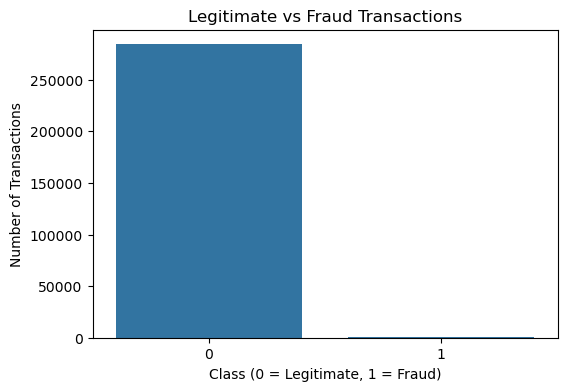

In [14]:
#Count Plot (Legitimate vs Fraud)

plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=data)
plt.title("Legitimate vs Fraud Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

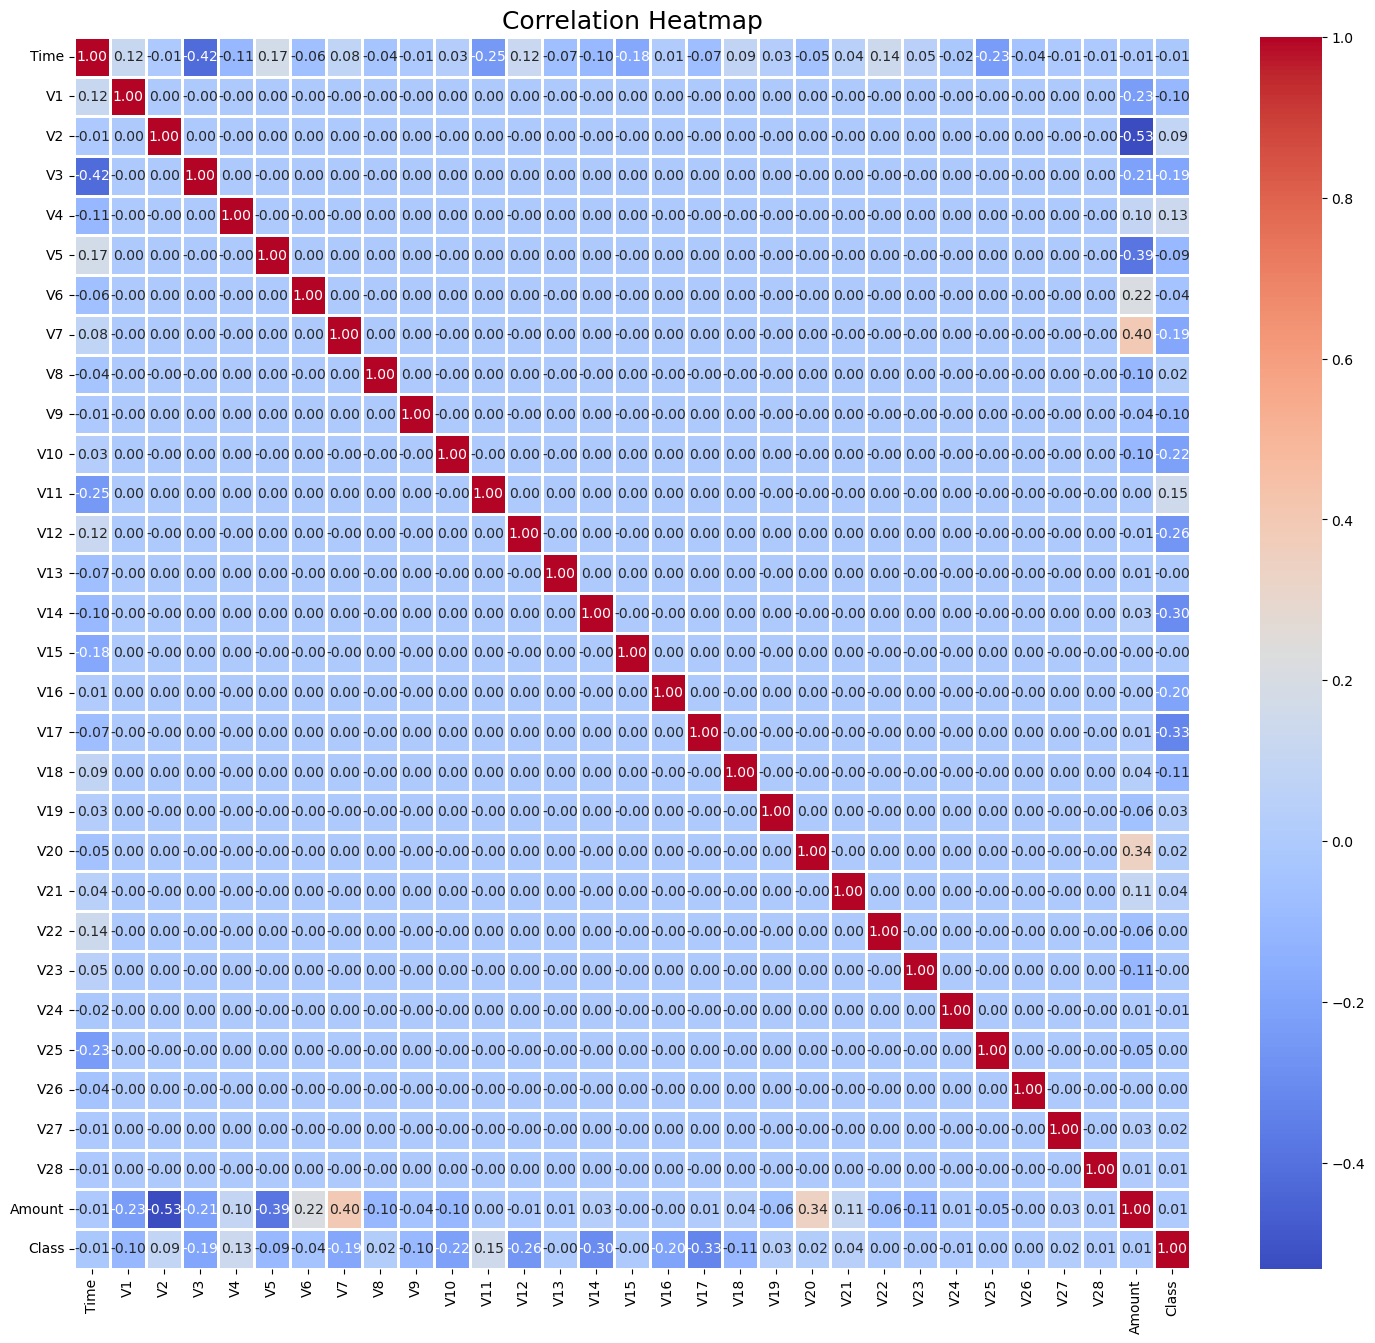

In [15]:
#Correlation Heatmap
plt.figure(figsize=(18,16))
sns.heatmap(data.corr(), cmap="coolwarm", annot=True, fmt='.2f', linewidths=0.9)
plt.title("Correlation Heatmap",fontsize= 18)
plt.show()

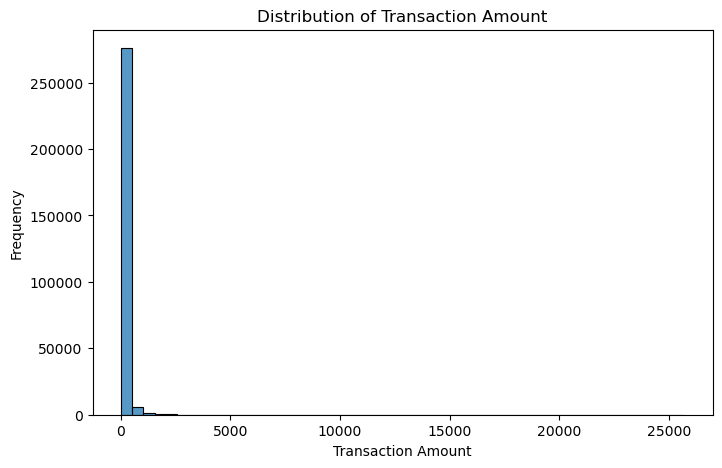

In [16]:
# Histogram of Transaction Amount

plt.figure(figsize=(8,5))
sns.histplot(data['Amount'], bins=50)
plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

Split data into Training and Testing Data

In [17]:
X = data.drop(columns='Class', axis=1)
y = data['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2, stratify=y)

In [18]:
print(X.shape, X_train.shape, X_test.shape)
print("Fraud cases in test set:", y_test.sum())

(284807, 30) (227845, 30) (56962, 30)
Fraud cases in test set: 98


In [19]:
# Undersampling on TRAINING data only (test data stays real and untouched)
train_data = pd.concat([X_train, y_train], axis=1)
legit_train = train_data[train_data.Class == 0]
fraud_train = train_data[train_data.Class == 1]

legit_sample = legit_train.sample(n=len(fraud_train), random_state=2)
balanced_train = pd.concat([legit_sample, fraud_train]).sample(frac=1, random_state=2)

X_train_bal = balanced_train.drop(columns='Class')
y_train_bal = balanced_train['Class']
print(y_train_bal.value_counts())

Class
0    394
1    394
Name: count, dtype: int64


Logistic Regression - Binary classification problems

In [20]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train_bal, y_train_bal)

#accuracy on train data (balanced training set)
y_train_pred = model.predict(X_train_bal)
train_accuracy = accuracy_score(y_train_pred, y_train_bal)
print("Accuracy on Training Data: ", train_accuracy)

Accuracy on Training Data:  0.950507614213198


In [21]:
#accuracy on test data

y_test_pred=model.predict(X_test)
test_accuracy = accuracy_score(y_test_pred, y_test) 
print("Accuracy on Testing Data: ", test_accuracy)

Accuracy on Testing Data:  0.9668024296899688


In [22]:
y_pred= model.predict(X_test)

#Classification reports like precision , f1_score, recall
print("Classification Report")
print(classification_report(y_test, y_pred))

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.95      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.96      0.54     56962
weighted avg       1.00      0.97      0.98     56962



Confusion Matrix
[[54978  1886]
 [    5    93]]


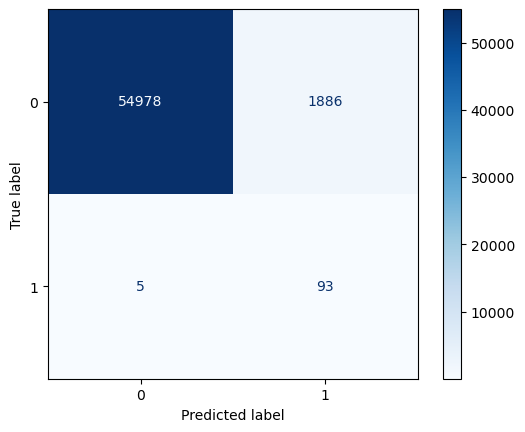

In [23]:
#Confusion matrix
print("Confusion Matrix")

cm = confusion_matrix(y_test, y_pred)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()

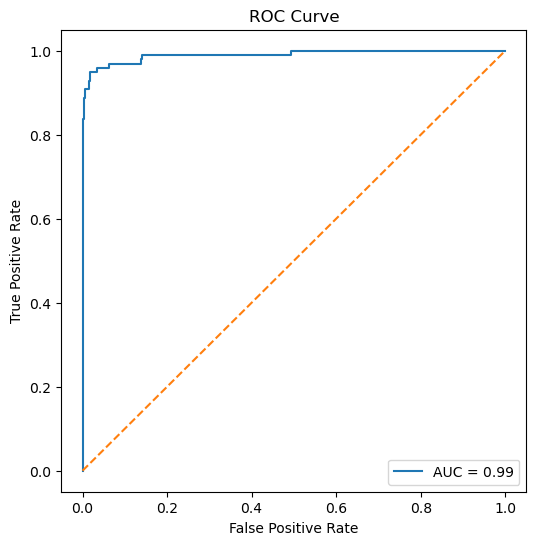

ROC-AUC Score: 0.9899432444615438


In [24]:
# Probability predictions
y_prob = model.predict_proba(X_test)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC score
auc = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

print("ROC-AUC Score:", auc)

In [25]:
# Threshold trade-off (y_prob comes from Cell 39)
for t in [0.5, 0.7, 0.9, 0.95, 0.99]:
    cm = confusion_matrix(y_test, (y_prob >= t).astype(int))
    print(f"Threshold {t}: Caught frauds = {cm[1,1]}, Missed frauds = {cm[1,0]}, False alarms = {cm[0,1]}")

Threshold 0.5: Caught frauds = 93, Missed frauds = 5, False alarms = 1886
Threshold 0.7: Caught frauds = 92, Missed frauds = 6, False alarms = 952
Threshold 0.9: Caught frauds = 89, Missed frauds = 9, False alarms = 490
Threshold 0.95: Caught frauds = 86, Missed frauds = 12, False alarms = 236
Threshold 0.99: Caught frauds = 82, Missed frauds = 16, False alarms = 79


Conclusion: Because the data is highly imbalanced, accuracy alone is misleading.
I undersampled only the training data and tested on the untouched real data.
The model catches ~95% of frauds but raises many false alarms.
Increasing the threshold reduces false alarms with a small loss in fraud detection.